# 신경망의 기울기 계산과 학습

같은 2층 신경망의 수치 미분·오차역전파 구현을 비교하고, Keras 구현과 학습 과정 대조.

학습 100개와 비교용 100개로 나눈 합성 데이터 사용. 비교용 데이터는 학습 곡선 확인에도 사용하므로 독립적인 최종 시험 결과로 해석하지 않음.

## 합성 데이터와 분포

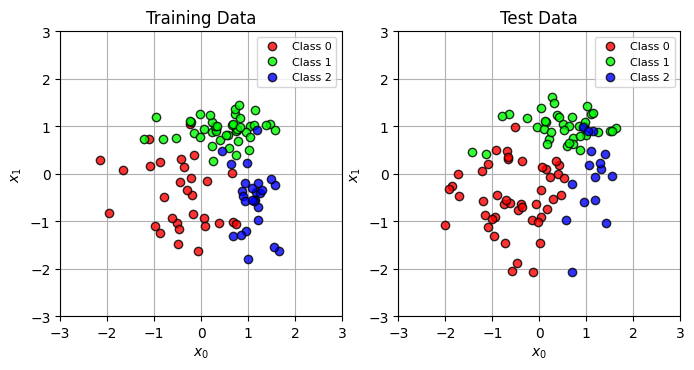

In [1]:
import numpy as np

# 데이터 생성
np.random.seed(seed = 1) # 난수를 고정
N = 200 # 데이터의 수
K = 3 #  분포의 수, 클래스의 수
T = np.zeros((N, 3), dtype = np.uint8)
X = np.zeros((N, 2))
X_range0 = [-3, 3]
X_range1 = [-3, 3]
Mu = np.array([[-.5, -.5], [.5, 1.0], [1, -.5]]) # 분포의 중심
Sig = np.array([[.7, .7], [.8, .3], [.3, .8]]) # 분포의 분산
Pi = np.array([0.4, 0.8, 1]) # 각 분포에 대한 비율

for n in range(N):
    wk = np.random.rand()
    
    for k in range(K):
        if wk < Pi[k]:
            T[n, k] = 1
            break
    
    for k in range(2):
        X[n, k] = np.random.randn() * Sig[T[n, :] == 1, k] + Mu[T[n, :] == 1, k]

        
# 2분류 데이터를 테스트 훈련 데이터로 분할
TestRatio = 0.5
X_n_training = int(N * TestRatio)
X_train = X[:X_n_training, :]
X_test = X[X_n_training:,:]
T_train = T[:X_n_training, :]
T_test = T[X_n_training:,:]






import matplotlib.pyplot as plt
%matplotlib inline

# 데이터를 그리기
def Show_data(x, t):
    wk, n = t.shape
    #c = [[0, 0, 0], [0.5, 0.5, 0.5], [1, 1, 1]] # 컬러 값 설정
    c = [[1, 0, 0], [0, 1, 0], [0, 0, 1]] # 컬러 값 설정 [r, g, b]
    
    for i in range(n):
         plt.plot(x[t[:, i] == 1, 0], x[t[:, i] == 1, 1], linestyle = 'none', markeredgecolor = 'black', marker = 'o', color = c[i], alpha = 0.8)
        # K 값을 0, 1, 2로 바꾸어 주면서 부류벡터 t 에 접근 부류번호가 일치하는 인덱스드을 모두 찾아준다
        # 따라서, 부류가 0번인 샘플들의 (x1, x2) 위치에 포인트를 먼저 다 찍고, 그 다음 부류로 순차적으로 찍게 된다
    plt.grid(True)
    
        
# 메인
plt.figure(figsize = (8, 3.7))
plt.subplot(1, 2, 1)
Show_data(X_train, T_train)
plt.xlim(X_range0)
plt.ylim(X_range1)
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')
plt.title('Training Data')
plt.legend(('Class 0','Class 1', 'Class 2'), loc='upper right', fontsize=8)

plt.subplot(1, 2, 2)
Show_data(X_test, T_test)
plt.xlim(X_range0)
plt.ylim(X_range1)
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')
plt.title('Test Data')
plt.legend(('Class 0','Class 1', 'Class 2'), loc='upper right', fontsize=8)

plt.show()


## 2층 피드 포워드 신경망의 구현


In [2]:
# 시그모이드 함수
def Sigmoid(x):
    y = 1 / (1 + np.exp(-x))
    return y


In [3]:
# 2층 피드 포워드 신경망 구현
def FNN(wv, M, K, x):
    # wv : 전체 가중치를 길이 {(D+1) * M} + {(M + 1) * K} 벡터로 전달
    # M : 은닉층의 뉴런 수
    # K : 출력층의 뉴런 수
    N, D = x.shape # N=샘플 수, D=특징벡터의 길이
    w = wv[: M * (D + 1)] # 은닉층의 가중치를 가져온다
    w = w.reshape((M, D + 1)) # M x (D+1) 행렬로 변환
    v = wv[M * (D + 1):] # 출력층의 가중치를 가져온다
    v = v.reshape((K, M + 1)) # K x (M+1) 행렬로 변환
    b = np.zeros((N, M + 1)) # 은닉층의 가중합을 저장하기 위한 공간
    z = np.zeros((N, M + 1)) # 은닉층의 출력을 저장하기 위한 공간
    a = np.zeros((N, K)) # 출력층의 가중합을 저장하기 위한 공간
    y = np.zeros((N, K)) # 출력층의 출력을 저장하기 위한 공간

    for n in range(N): # 개별 샘플 별 계산
        # 은닉층의 계산
        for m in range(M):
            b[n, m] = np.dot(w[m, :], np.r_[x[n, :], 1]) # 가중합 연산
            # np.r_[x[n, :], 1] 바이어스를 추가하는 부분
            z[n, m] = Sigmoid(b[n, m]) # 활성화 함수

        # 출력층의 계산
        z[n, M] = 1 # 바이어스 값 1 저장
        wkz = 0 # 소프트맥스 함수의 분모 값 저장을 위한 변수

        for k in range(K):
            a[n, k] = np.dot(v[k, :], z[n, :])
            wkz = wkz + np.exp(a[n, k]) # 소프트맥스 함수의 분모 값 계산

        for k in range(K):
            y[n, k] = np.exp(a[n, k]) / wkz # 최종 출력 계산

    return y, a, z, b


In [4]:
WV = np.ones(15)
M = 2
K = 3
FNN(WV, M, K, X_train[:2, :])


(array([[0.33333333, 0.33333333, 0.33333333],
        [0.33333333, 0.33333333, 0.33333333]]),
 array([[2.6971835 , 2.6971835 , 2.6971835 ],
        [1.49172649, 1.49172649, 1.49172649]]),
 array([[0.84859175, 0.84859175, 1.        ],
        [0.24586324, 0.24586324, 1.        ]]),
 array([[ 1.72359839,  1.72359839,  0.        ],
        [-1.12079826, -1.12079826,  0.        ]]))

## 평균 교차 엔트로피 오차


In [5]:
# 평균 교차 엔트로피 오차
def CE_FNN(wv, M, K, x, t):
    N, D = x.shape
    y, a, z, b = FNN(wv, M, K, x)
    ce = -np.dot(np.log(y.reshape(-1)), t.reshape(-1)) / N
    # N x K 행렬인 y 와 t 행렬을 reshape(-1) 을 통하여
    # 1차원 행벡터로 변환 시킨 후 내적을 구하면
    # 교차 엔트로피 오차를 쉽게 구할 수 있다
    return ce


In [6]:
WV = np.ones(15)
M = 2
K = 3
CE_FNN(WV, M, K, X_train[:2, :], T_train[:2, :])


1.0986122886681098

## 수치 미분법


In [7]:
def dCE_FNN_num(wv, M, K, x, t):
    epsilon = 0.001
    dwv = np.zeros_like(wv)

    for iwv in range(len(wv)): # 모든 가중치에 대해 수행
        wv_modified = wv.copy()
        wv_modified[iwv] = wv[iwv] - epsilon # w_m = (w-epsilon)
        mse1 = CE_FNN(wv_modified, M, K, x, t)
        wv_modified[iwv] = wv[iwv] + epsilon # w_m = (w+epsilon)
        mse2 = CE_FNN(wv_modified, M, K, x, t)
        dwv[iwv] = (mse2 - mse1) / (2 * epsilon)

    return dwv


## 수치 미분법에 의한 경사 하강법


In [8]:
def Fit_FNN_num(wv_init, M, K, x_train, t_train, x_test, t_test, n, alpha):
    wvt = wv_init
    err_train = np.zeros(n)
    err_test = np.zeros(n)
    wv_hist = np.zeros((n, len(wv_init)))
    epsilon = 0.001

    for i in range(n):
        # for 루프 내에서 wvt 를 dCE_FNN_num 으로 갱신
        # 매번 훈련 데이터의 오차와 테스트 데이터의 오차를 계산
        wvt = wvt - alpha * dCE_FNN_num(wvt, M, K, x_train, t_train)
        err_train[i] = CE_FNN(wvt, M, K, x_train, t_train)
        err_test[i] = CE_FNN(wvt, M, K, x_test, t_test)
        wv_hist[i, :] = wvt

    return wvt, wv_hist, err_train, err_test


In [9]:
# 학습을 위한 파라미터 설정
M = 2 # 은닉층의 뉴런 수
K = 3 # 출력의 수(클래스의 수)

# 가중치 랜덤 초기화
np.random.seed(1)
WV_init = np.random.normal(0, 0.01, M * 3 + K * (M + 1))

N_step = 1000 # 학습 횟수
alpha = 0.5 # 학습률


In [10]:
import time

startTime = time.time()
WV, WV_hist, Err_train, Err_test = Fit_FNN_num(
    WV_init, M, K, X_train, T_train, X_test, T_test, N_step, alpha)

caculation_time = time.time() - startTime
print("Caculation time: {:.3f} sec.".format(caculation_time))


Caculation time: 72.031 sec.


In [11]:
# 수치 미분 학습 결과 저장
WV_num = WV.copy()
WV_hist_num = WV_hist.copy()
Err_train_num = Err_train.copy()
Err_test_num = Err_test.copy()


## 수치 미분 학습 곡선

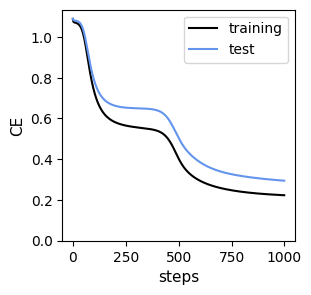

In [12]:
# 학습 오차의 표시
plt.figure(figsize = (3, 3))
plt.plot(Err_train, 'black', label = 'training')
plt.plot(Err_test, 'cornflowerblue', label = 'test')
plt.xlabel('steps', fontsize = 11)
plt.ylabel('CE', fontsize = 11)
plt.ylim(0, )
plt.legend()
plt.show()


## 가중치 변화

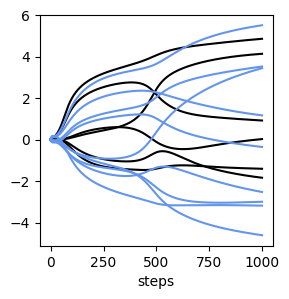

Black: w, Cornflowerblue: v


In [13]:
# 가중치의 시간 변화의 표시
plt.figure(figsize = (3, 3))
plt.plot(WV_hist[:, : M * 3], 'black')
plt.plot(WV_hist[:, M * 3 :], 'cornflowerblue')
plt.xlabel("steps")
plt.show()
print("Black: w, Cornflowerblue: v")


## 분류 경계

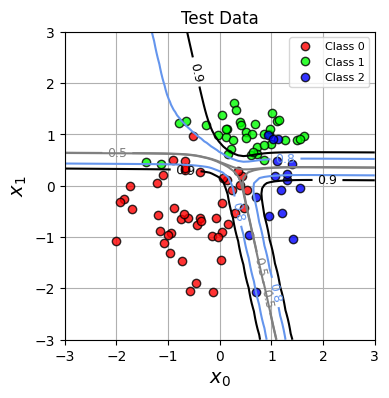

In [14]:
# 경계선 표시 함수
# 각각의 카테고리에서 0.5, 0.8, 0.9 이상의 출력을 얻을 수 있는 영역을 등고선으로 표시
def show_FNN(wv, M, K):
    xn = 60 # 등고선 표시 해상도
    x0 = np.linspace(X_range0[0], X_range0[1], xn)
    x1 = np.linspace(X_range1[0], X_range1[1], xn)
    xx0, xx1 = np.meshgrid(x0, x1)
    x = np.c_[np.reshape(xx1, (xn * xn, 1)), np.reshape(xx0, (xn * xn, 1))] # np.c_ column 추가
    y, a, z, b = FNN(wv, M, K, x)
    # 이미 바깥에서 figure를 만들었으므로 여기서는 새 figure를 만들지 않는다
    
    for ic in range(K):
        f = y[: , ic]
        f = f.reshape(xn, xn)
        f = f.T
        cont = plt.contour(xx0, xx1, f, levels = [0.5, 0.8, 0.9], colors = ['gray', 'cornflowerblue', 'black'])
        cont.clabel(fmt = '%1.1f', fontsize = 9)
        
    plt.xlim(X_range0)
    plt.ylim(X_range1)
    
    
# 경계선 표시
plt.figure(figsize = (4, 4))
Show_data(X_test,T_test)
show_FNN(WV, M, K)
plt.xlabel('$x_0$', fontsize = 14)
plt.ylabel('$x_1$', fontsize = 14)
plt.title('Test Data')
plt.legend(('Class 0','Class 1', 'Class 2'), loc='upper right', fontsize=8)
plt.show()


## 오차 역전파법의 구현


In [15]:
# 오차 역전파에 의한 그레디언트 구하기 구현
def dCE_FNN(wv, M, K, x, t):
    N, D = x.shape

    # 가중치 벡터 wv 를 가중치 행렬 w 와 v 로 분리
    w = wv[: M * (D + 1)]
    w = w.reshape(M, (D + 1))
    v = wv[M * (D + 1):]
    v = v.reshape((K, M + 1))

    # ① 전방계산: x 를 입력하여 y, a, z, b 를 얻음
    y, a, z, b = FNN(wv, M, K, x)

    # 출력 변수의 준비
    dwv = np.zeros_like(wv)
    dw = np.zeros((M, D + 1))
    dv = np.zeros((K, M + 1))
    delta1 = np.zeros(M) # 1층 오차
    delta2 = np.zeros(K) # 2층 오차

    for n in range(N):
        # ② 출력층의 오차(delta2) 구하기
        for k in range(K):
            delta2[k] = (y[n, k] - t[n, k])
        # ③ 은닉층의 오차(delta1) 구하기
        for j in range(M):
            delta1[j] = z[n, j] * (1 - z[n, j]) * np.dot(v[:, j], delta2)
        # ④ v 의 그레디언트 dv
        for k in range(K):
            dv[k, :] = dv[k, :] + delta2[k] * z[n, :] / N
        # ④ w 의 그레디언트 dw
        for j in range(M):
            dw[j, :] = dw[j, :] + delta1[j] * np.r_[x[n, :], 1] / N

    # 그레디언트 행렬 dw 와 dv 를 그레디언트 벡터 dwv 로 만들기
    dwv = np.c_[dw.reshape((1, M * (D + 1))), dv.reshape((1, K * (M + 1)))]
    dwv = dwv.reshape(-1)

    return dwv


In [16]:
# 뉴런수
M = 2
K = 3
# 사용할 데이터 수
N = 2
nWV = M * 3 + K * (M+1)
np.random.seed(1)
# 가중치 초기화
WV = np.random.normal(0, 1, nWV)

# 해석적 미분(오차역전파)
dWV_ana = dCE_FNN(WV, M, K, X_train[: N, :], T_train[: N, :])
print("analytical dWV")
print(dWV_ana)

# 수치적 미분(근사화 미분)
dWV_num = dCE_FNN_num(WV, M, K, X_train[: N, :], T_train[: N, :])
print("numerical dWV")
print(dWV_num)


analytical dWV
[ 0.08848131  0.19158    -0.051398    0.01281536 -0.14468029 -0.14242768
 -0.02992012  0.01351315 -0.11115649 -0.10104422 -0.09427964 -0.46855604
  0.13096434  0.08076649  0.57971253]
numerical dWV
[ 0.0884813   0.19157999 -0.05139799  0.01281536 -0.14468029 -0.14242768
 -0.02992012  0.01351315 -0.11115648 -0.10104422 -0.09427964 -0.46855603
  0.13096434  0.08076649  0.57971252]


## 기울기 계산 결과 비교

Text(0.5, 0, '$i$')

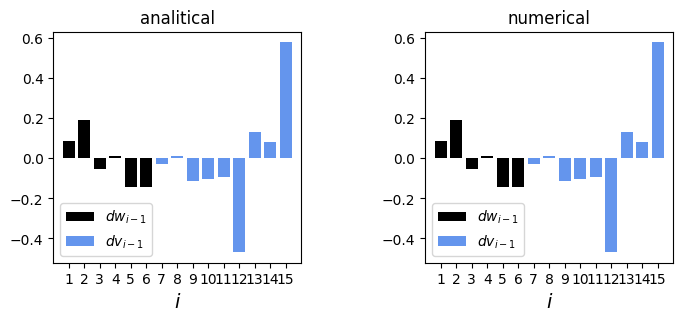

In [17]:
# Show dWV
def Show_dWV(wv, M):
    N = wv.shape[0]
    plt.bar(range(1, M * 3 + 1), wv[ : M * 3], align = "center", color = 'black', label = '$dw_{i-1}$')
    plt.bar(range(M * 3 + 1, N + 1), wv[M * 3 : ], align = "center", color = 'cornflowerblue', label = '$dv_{i-1}$')
    plt.xticks(range(1, N + 1))
    plt.xlim(0, N +1)
    plt.legend(loc = "lower left", fontsize = 14)
    plt.xlabel('$i$', fontsize=14)

    
plt.figure(figsize = (8, 3))
plt.subplots_adjust(wspace = 0.5)
plt.subplot(1, 2, 1)
Show_dWV(dWV_ana, M)
plt.title('analitical')
plt.legend(loc = "lower left")
plt.xlabel('$i$', fontsize=14)

plt.subplot(1, 2, 2)
Show_dWV(dWV_num, M)
plt.title('numerical')
plt.legend(loc = "lower left")
plt.xlabel('$i$', fontsize=14)


## 오차역전파 학습

In [18]:
# 오류역전파에 의한 경사하강법

def Fit_FNN(wv_init, M, K, x_train, t_train, x_test, t_test, n, alpha):
    wv = wv_init.copy()
    err_train = np.zeros(n)
    err_test = np.zeros(n)
    wv_hist = np.zeros((n, len(wv_init)))

    for i in range(n):
        wv = wv - alpha * dCE_FNN(wv, M, K, x_train, t_train)
        err_train[i] = CE_FNN(wv, M, K, x_train, t_train)
        err_test[i] = CE_FNN(wv, M, K, x_test, t_test)
        wv_hist[i, :] = wv

    return wv, wv_hist, err_train, err_test


In [19]:
import time

start_time = time.time()
# 각 층의 뉴런 수
M = 2
K = 3
# 가중치 초기화
np.random.seed(1)
WV_init = np.random.normal(0, 0.01, M * 3 + K * (M + 1))
N_step = 1000 # 학습 횟수
alpha = 0.5 # 학습률

WV, WV_hist, Err_train, Err_test = Fit_FNN(WV_init, M, K, X_train, T_train,
                                          X_test, T_test, N_step, alpha)

calculation_time = time.time() - start_time
print("calculation time: {:.3f} sec".format(calculation_time))


calculation time: 9.622 sec


In [20]:
# 오차역전파 학습 결과 저장
WV_bp = WV.copy()
WV_hist_bp = WV_hist.copy()
Err_train_bp = Err_train.copy()
Err_test_bp = Err_test.copy()


## 오차역전파 학습 결과

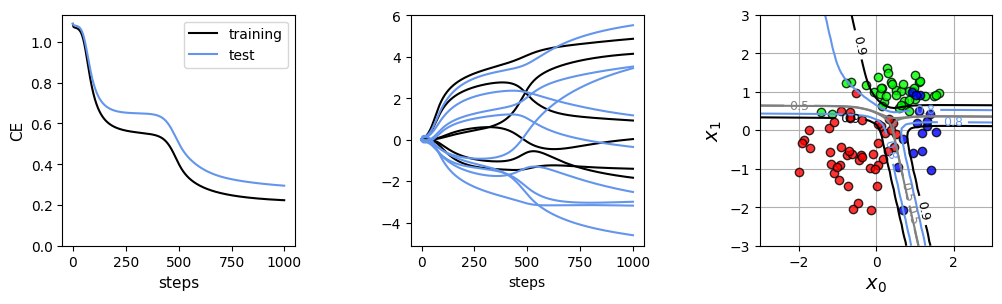

In [21]:
plt.figure(figsize = (12, 3))
plt.subplots_adjust(wspace = 0.5)

# 학습 오차의 표시
plt.subplot(1, 3, 1)
plt.plot(Err_train, 'black', label = 'training')
plt.plot(Err_test, 'cornflowerblue', label = 'test')
plt.xlabel('steps', fontsize = 11)
plt.ylabel('CE', fontsize = 11)
plt.ylim(0, )
plt.legend()

# 가중치의 시간 변화 표시
plt.subplot(1, 3, 2)
plt.plot(WV_hist[:, : M * 3], 'black')
plt.plot(WV_hist[:, M * 3 :], 'cornflowerblue')
plt.xlabel("steps")

# 경계선 표시
plt.subplot(1, 3, 3)
Show_data(X_test,T_test)
show_FNN(WV, M, K)
plt.xlabel('$x_0$', fontsize = 14)
plt.ylabel('$x_1$', fontsize = 14)
plt.show()


## 텐서플로로 신경망 모델 구현


In [22]:
import tensorflow.keras.optimizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation

np.random.seed(1) # 난수 초기화

# Sequential 모델 작성
# Sequential 클래스에서 생성된 객체, model 에 층을 추가해 네트워크 구조를 정의
model = Sequential()

# 첫번째 은닉층
model.add(Dense(2, input_dim=2, activation='sigmoid', kernel_initializer='uniform'))

# 출력층
model.add(Dense(3, activation='softmax', kernel_initializer='uniform'))

# 최적화기 설정
sgd = tensorflow.keras.optimizers.SGD(learning_rate=1.0, momentum=0.0, nesterov=False)

# 모델 컴파일
model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])


In [23]:
model.summary()


Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 2)                 6         


 dense_1 (Dense)             (None, 3)                 9         


Total params: 15


Trainable params: 15


Non-trainable params: 0


_________________________________________________________________


In [24]:
start_time = time.time()

history = model.fit(X_train, T_train, epochs=1000, batch_size=100, verbose=0,
                    validation_data=(X_test, T_test))

calculation_time = time.time() - start_time


In [25]:
print("Calculation time: {:.3f} sec".format(calculation_time))


Calculation time: 13.024 sec


In [26]:
history = history.history
history.keys()


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [27]:
# Keras 학습 결과 저장
history_keras = history.copy()


In [28]:
score = model.evaluate(X_test, T_test, verbose=0)

print("crosse entropy {:.2f}, accuracy {:.2f}".format(score[0], score[1]))


crosse entropy 0.27, accuracy 0.90


## Keras 분류 경계

  1/113 [..............................] - ETA: 6s

113/113 [==============================] - 0s 318us/step


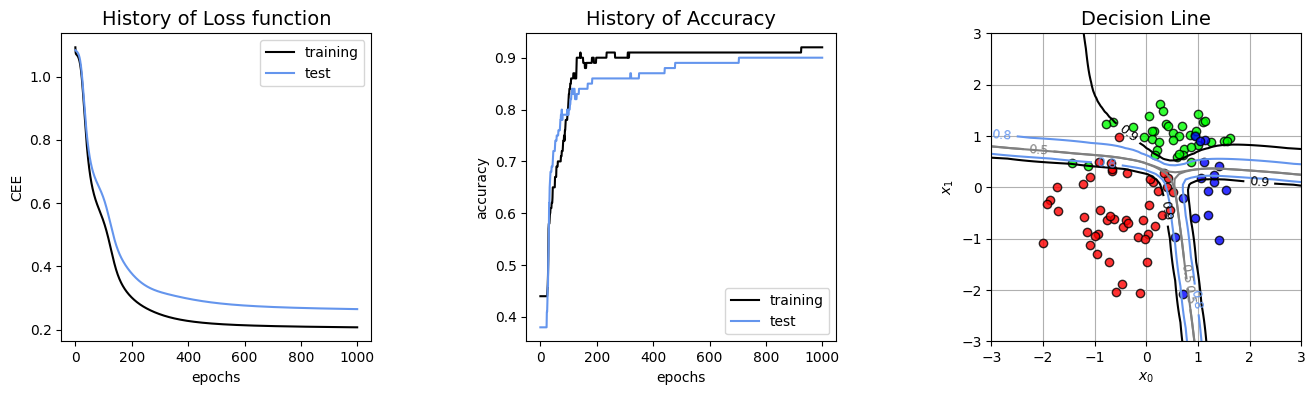

In [29]:
import matplotlib.pyplot as plt
%matplotlib inline

# 데이터를 그리기
def Show_data(x, t):
    wk, n = t.shape
    c = [[0, 0, 0], [0.5, 0.5, 0.5], [1, 1, 1]] # 컬러 값 설정
    c = [[1, 0, 0], [0, 1, 0], [0, 0, 1]] # 컬러 값 설정 [r, g, b]
    
    for i in range(n):
         plt.plot(x[t[:, i] == 1, 0], x[t[:, i] == 1, 1], linestyle = 'none', markeredgecolor = 'black', marker = 'o', color = c[i], alpha = 0.8)
        # K 값을 0, 1, 2로 바꾸어 주면서 부류벡터 t 에 접근 부류번호가 일치하는 인덱스드을 모두 찾아준다
        # 따라서, 부류가 0번인 샘플들의 (x1, x2) 위치에 포인트를 먼저 다 찍고, 그 다음 부류로 순차적으로 찍게 된다
    plt.grid(True)
    
# 리스트 7-2-(4)
plt.figure(figsize = (16, 4))
plt.subplots_adjust(wspace = 0.5)

# 학습 곡선 표시
plt.subplot(1, 3, 1)
plt.plot(history['loss'], 'black', label = 'training')
# (A) 학습 과정의 훈련 데이터의 교차 엔트로피 오차의 시계열 정보
plt.plot(history['val_loss'], 'cornflowerblue', label ='test')
# (B) 학습 과정의 평가용 데이터의의 교차 엔트로피 오차
plt.legend()
plt.xlabel('epochs')
plt.ylabel('CEE')
plt.title('History of Loss function', fontsize = 14)


# 정확도 표시
plt.subplot(1, 3, 2)
plt.plot(history['accuracy'], 'black', label = 'training') 
# (C) 훈련 데이터의 정답률 변화
plt.plot(history['val_accuracy'], 'cornflowerblue', label = 'test')
# (D) 평가용 데이터의 정답률 변화
plt.legend()
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.title('History of Accuracy', fontsize = 14)


# 경계선 표시
plt.subplot(1, 3, 3)
Show_data(X_test, T_test)
xn = 60 # 등고선 표시 해상도
x0 = np.linspace(X_range0[0], X_range0[1], xn)
x1 = np.linspace(X_range1[0], X_range1[1], xn)
xx0, xx1 = np.meshgrid(x0, x1)
x = np.c_[np.reshape(xx0, xn * xn, 'F'), np.reshape(xx1, xn * xn, 'F')] # np.c_ column 추가
#y, a, z, b = FNN(wv, M, K, x)
y = model.predict(x) # (E) 학습이 완료된 모델에 입력 x에 대한  출력
K = 3

for ic in range(K):
    f = y[: , ic]
    f = f.reshape(xn, xn)
    f = f.T
    cont = plt.contour(xx0, xx1, f, levels = [0.5, 0.8, 0.9], colors = ['gray', 'cornflowerblue', 'black'])
    cont.clabel(fmt = '%1.1f', fontsize = 9)

plt.xlim(X_range0)
plt.ylim(X_range1)
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')
plt.title('Decision Line', fontsize = 14)

plt.show()


## 학습 결과 비교


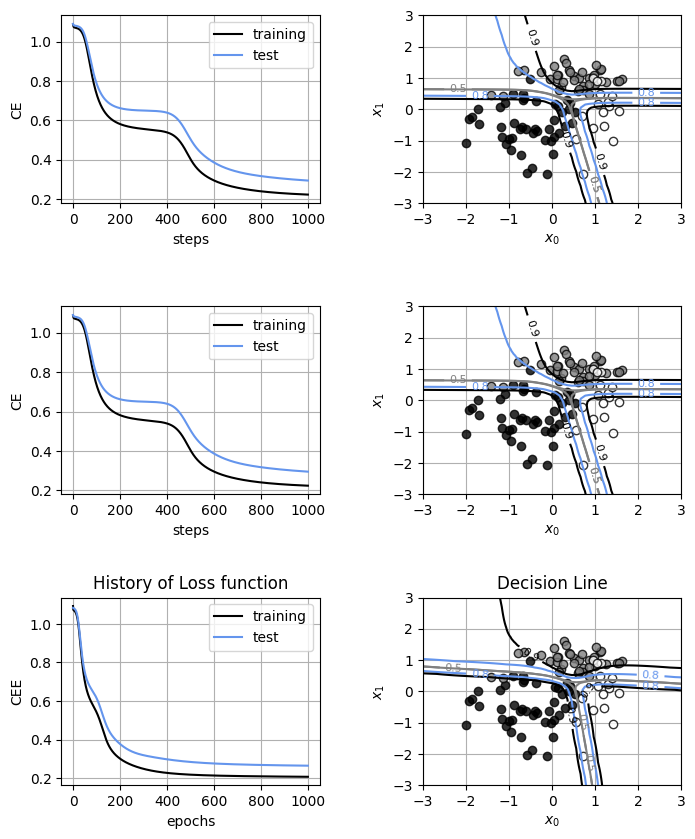

In [30]:
# 학습 결과 비교
# 위에서 부터
# 수치 미분에 의한 학습
# 해석적 미분(오차역전파)에 의한 학습
# 케라스를 이용한 학습

def Show_data_compare(ax, x, t):
    wk, n = t.shape
    c = [[0, 0, 0], [0.5, 0.5, 0.5], [1, 1, 1]]
    
    for i in range(n):
        ax.plot(x[t[:, i] == 1, 0], x[t[:, i] == 1, 1],
                linestyle='none', markeredgecolor='black', marker='o',
                color=c[i], alpha=0.8)
    ax.grid(True)


def Show_FNN_compare(ax, wv, M, K):
    xn = 60
    x0 = np.linspace(X_range0[0], X_range0[1], xn)
    x1 = np.linspace(X_range1[0], X_range1[1], xn)
    xx0, xx1 = np.meshgrid(x0, x1)
    x = np.c_[np.reshape(xx0, xn * xn, 'F'), np.reshape(xx1, xn * xn, 'F')]
    y, a, z, b = FNN(wv, M, K, x)

    for ic in range(K):
        f = y[:, ic]
        f = f.reshape(xn, xn)
        f = f.T
        cont = ax.contour(xx0, xx1, f, levels=[0.5, 0.8, 0.9],
                          colors=['gray', 'cornflowerblue', 'black'])
        cont.clabel(fmt='%1.1f', fontsize=8)

    ax.set_xlim(X_range0)
    ax.set_ylim(X_range1)


def Show_keras_compare(ax, model):
    xn = 60
    x0 = np.linspace(X_range0[0], X_range0[1], xn)
    x1 = np.linspace(X_range1[0], X_range1[1], xn)
    xx0, xx1 = np.meshgrid(x0, x1)
    x = np.c_[np.reshape(xx0, xn * xn, 'F'), np.reshape(xx1, xn * xn, 'F')]
    y = model.predict(x, verbose=0)

    for ic in range(3):
        f = y[:, ic]
        f = f.reshape(xn, xn)
        f = f.T
        cont = ax.contour(xx0, xx1, f, levels=[0.5, 0.8, 0.9],
                          colors=['gray', 'cornflowerblue', 'black'])
        cont.clabel(fmt='%1.1f', fontsize=8)

    ax.set_xlim(X_range0)
    ax.set_ylim(X_range1)


plt.figure(figsize=(8, 10))
plt.subplots_adjust(hspace=0.55, wspace=0.4)

# 수치 미분
ax = plt.subplot(3, 2, 1)
ax.plot(Err_train_num, 'black', label='training')
ax.plot(Err_test_num, 'cornflowerblue', label='test')
ax.set_xlabel('steps')
ax.set_ylabel('CE')
ax.legend()
ax.grid(True)

ax = plt.subplot(3, 2, 2)
Show_data_compare(ax, X_test, T_test)
Show_FNN_compare(ax, WV_num, M, K)
ax.set_xlabel('$x_0$')
ax.set_ylabel('$x_1$')

# 오차역전파
ax = plt.subplot(3, 2, 3)
ax.plot(Err_train_bp, 'black', label='training')
ax.plot(Err_test_bp, 'cornflowerblue', label='test')
ax.set_xlabel('steps')
ax.set_ylabel('CE')
ax.legend()
ax.grid(True)

ax = plt.subplot(3, 2, 4)
Show_data_compare(ax, X_test, T_test)
Show_FNN_compare(ax, WV_bp, M, K)
ax.set_xlabel('$x_0$')
ax.set_ylabel('$x_1$')

# Keras
ax = plt.subplot(3, 2, 5)
ax.plot(history_keras['loss'], 'black', label='training')
ax.plot(history_keras['val_loss'], 'cornflowerblue', label='test')
ax.set_xlabel('epochs')
ax.set_ylabel('CEE')
ax.set_title('History of Loss function')
ax.legend()
ax.grid(True)

ax = plt.subplot(3, 2, 6)
Show_data_compare(ax, X_test, T_test)
Show_keras_compare(ax, model)
ax.set_xlabel('$x_0$')
ax.set_ylabel('$x_1$')
ax.set_title('Decision Line')

plt.show()


## 학습 결과 비교 정리

위의 세 결과는 모두 같은 데이터를 분류하기 위한 2층 피드 포워드 신경망 학습 결과이다. 차이는 매개변수인 가중치를 어떻게 업데이트하느냐에 있다.

첫 번째는 수치 미분에 의한 학습이다. 각 가중치를 아주 조금 줄였을 때와 늘렸을 때의 오차 차이를 이용해서 기울기를 근사한다. 그래서 구현은 직관적이지만, 모든 가중치마다 오차를 여러 번 다시 계산해야 하므로 학습 시간이 오래 걸린다.

두 번째는 해석적 미분, 즉 오차역전파에 의한 학습이다. 전방 계산으로 출력값을 구한 뒤, 출력층의 오차를 은닉층 방향으로 되돌려 보내면서 기울기를 직접 계산한다. 수치 미분처럼 가중치 하나하나를 바꿔가며 다시 계산하지 않기 때문에 더 빠르다. 이론적으로는 수치 미분과 거의 같은 방향으로 가중치가 업데이트되므로 그래프와 결정 경계도 비슷하게 나온다.

세 번째는 Keras를 이용한 학습이다. Keras가 내부적으로 순전파, 오차역전파, 가중치 업데이트를 자동으로 처리한다. 직접 구현한 코드와 같은 신경망 구조를 사용하지만, 미니배치 처리, 초기 가중치 생성, 데이터 셔플, 최적화기 구현 방식 때문에 결과가 완전히 똑같지는 않을 수 있다.

정리하면, 수치 미분은 이해하기 쉽지만 느리고, 오차역전파는 같은 목적을 훨씬 빠르게 계산하며, Keras는 이 과정을 라이브러리로 간단하게 실행하는 방법이다. 세 방법 모두 학습이 진행될수록 교차 엔트로피 오차가 감소하고, 테스트 데이터에 대한 클래스 경계선이 형성되는 것을 확인할 수 있다.
